# Experiment 2 — Double-Pipe Heat Exchanger: Conjugate Heat Transfer by the Finite Difference Method

**Aim.** Predict how heat moves from a hot stream to a cold stream across a solid wall, by solving *one* finite-difference field for the whole cross-section — both fluids **and** the wall — at the same time.

**Method.** Pure finite differences: Taylor-series stencils on a structured grid, marched to steady state, all in this notebook. No finite-volume machinery, no external solver scripts, no VTK round-trip just to make a plot — every array below is the field actually being solved.

## The physical picture

A real double-pipe heat exchanger is two concentric tubes: one fluid in the inner tube, the other in the annular gap, separated by the tube wall. To keep the grid a simple Cartesian one — and to keep the focus on *conjugate* heat transfer rather than on cylindrical geometry — we unroll that arrangement into three flat layers stacked in $y$:

```
 y = Ly ┌───────────────────────────────┐
        │         HOT channel           │  ---->   (or <---- if counter-flow)
        ├───────────────────────────────┤
        │         solid WALL             │
        ├───────────────────────────────┤
        │         COLD channel          │  ---->
 y = 0  └───────────────────────────────┘
        x = 0                       x = Lx
```

Both channels carry a **prescribed**, fully-developed laminar (parabolic) velocity profile — we are solving only the energy equation here, not the momentum equation, so the flow field is an input, not an output. Everything below is where the finite-difference method does its work.

## Governing equation

Assume steady, incompressible flow, constant properties within each zone, no viscous dissipation and no internal heat generation. The non-dimensional energy equation, written as *one* equation over the whole rectangle, is

$$
u(x,y)\,\frac{\partial T}{\partial x} \;=\; \frac{\partial}{\partial x}\!\left(D(x,y)\,\frac{\partial T}{\partial x}\right) + \frac{\partial}{\partial y}\!\left(D(x,y)\,\frac{\partial T}{\partial y}\right)
$$

with two coefficient fields that both jump at the fluid/wall interfaces:

- $u(x,y)$ — the prescribed axial velocity: parabolic in each fluid channel, **zero** in the solid wall.
- $D(x,y)$ — a diffusivity field, built from the Reynolds and Prandtl numbers and the wall/fluid conductivity ratio $k_s/k_f$:

$$
D_{\text{cold}} = \frac{1}{Re_{\text{cold}}\,Pr}, \qquad
D_{\text{hot}} = \frac{1}{Re_{\text{hot}}\,Pr}, \qquad
D_{\text{wall}} = \frac{k_s}{k_f}\cdot\frac{D_{\text{hot}}+D_{\text{cold}}}{2}
$$

**Why one equation for three zones?** Because $u=0$ turns it into pure conduction inside the wall automatically — $\partial_x(D\partial_xT)+\partial_y(D\partial_yT)=0$ — with no separate equation to write and stitch on by hand. Solving one field over the whole rectangle, with $u(x,y)$ and $D(x,y)$ simply changing value from node to node, is what makes this a **conjugate** solution: continuity of temperature and of heat flux across the two interfaces falls out of the discretisation on its own (next section), rather than being imposed as an extra condition.

### Boundary conditions

| Edge | Condition | Meaning |
|---|---|---|
| Hot-channel inlet | $T=T_{hot,in}$ | fixed inlet temperature |
| Hot-channel outlet | $\partial T/\partial x=0$ | fully-developed outflow |
| Cold-channel inlet | $T=T_{cold,in}$ | fixed inlet temperature |
| Cold-channel outlet | $\partial T/\partial x=0$ | fully-developed outflow |
| Wall's own left & right ends | $\partial T/\partial x=0$ | no axial heat loss out the ends of the wall |
| Top & bottom of the domain | $\partial T/\partial y=0$ | insulated outer surfaces |

For counter-flow the cold stream enters at $x=L_x$ and exits at $x=0$, so its inlet/outlet columns swap sides — handled in the boundary-condition function below.

## Finite-difference discretisation

Grid: $n_x\times n_y$ nodes, uniform spacing $\Delta x,\Delta y$. Every derivative below is an ordinary Taylor-series finite difference — no control volume, no face flux, no interpolation scheme, just values at nodes.

**Convection — upwind first difference.** At the Peclet numbers here ($Re\cdot Pr$ of several hundred), a central difference of $\partial T/\partial x$ oscillates — the classic symptom of the FDM instability at high cell-Peclet number. The standard cure is a one-sided, upwind difference:

$$
\left.\frac{\partial T}{\partial x}\right|_{i,j} \approx
\begin{cases}
\dfrac{T_{i,j}-T_{i-1,j}}{\Delta x}, & u_{i,j}\ge 0\\[6pt]
\dfrac{T_{i+1,j}-T_{i,j}}{\Delta x}, & u_{i,j}< 0
\end{cases}
$$

**Diffusion — variable-coefficient second difference.** Because $D$ jumps at the fluid/wall interface, multiplying a plain central second difference by a single $D_{i,j}$ would silently break flux continuity right at the interface. Instead we difference the flux form directly, evaluating $D$ at each half-node with a **harmonic mean**:

$$
\left.\frac{\partial}{\partial x}\!\left(D\frac{\partial T}{\partial x}\right)\right|_{i,j} \approx
\frac{D_{i+\frac12,j}(T_{i+1,j}-T_{i,j}) - D_{i-\frac12,j}(T_{i,j}-T_{i-1,j})}{\Delta x^2},
\qquad
D_{i+\frac12,j}=\frac{2\,D_{i,j}D_{i+1,j}}{D_{i,j}+D_{i+1,j}}
$$

(same construction in $y$). The harmonic mean is exactly the classical nodal-network result for two conduction resistances in series — it's what makes the wall/fluid interface conserve heat flux to machine precision, as you'll see in the energy balance further down.

**Marching to steady state.** Rather than assemble and invert the resulting system, we march an explicit pseudo-time step until nothing changes:

$$
T_{i,j}^{\,n+1} = T_{i,j}^{\,n} + \Delta t\left[-u_{i,j}\left.\frac{\partial T}{\partial x}\right|^n_{i,j} + \left.\frac{\partial}{\partial x}\!\Big(D\frac{\partial T}{\partial x}\Big)\right|^n_{i,j} + \left.\frac{\partial}{\partial y}\!\Big(D\frac{\partial T}{\partial y}\Big)\right|^n_{i,j}\right]
$$

An explicit update like this is only stable below both the diffusive limit and the convective (CFL) limit. We compute both directly from the grid and the property fields and take whichever is tighter, with a safety factor:

$$
\Delta t \le \text{safety}\times\min\left(\underbrace{\frac{1}{2D_{\max}\left(1/\Delta x^2+1/\Delta y^2\right)}}_{\text{diffusive limit}},\ \underbrace{\frac{\Delta x}{|u|_{\max}}}_{\text{CFL limit}}\right)
$$

Skipping this — e.g. using one fixed relaxation factor regardless of the grid or the conductivity ratio — is the single most common way a first convection-diffusion FDM solver diverges: the wall's diffusivity can be $\sim\!100\times$ the fluid's, and a $\Delta t$ that's stable for the fluid is easily $100\times$ too large for the wall.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-94irh_e9 because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


In [2]:
# ============================== 1. Grid and zone layout ==============================
# The domain is Lx (flow direction) by Ly (cross-stream). ny is split into three
# stacked bands: cold channel (bottom), wall (middle), hot channel (top).

Lx, Ly = 8.0, 2.0     # domain size

nx      = 160          # nodes along the flow direction
ny_cold = 20            # nodes across the cold channel
ny_wall = 6             # nodes across the solid wall
ny_hot  = 20             # nodes across the hot channel
ny = ny_cold + ny_wall + ny_hot

if nx < 10 or min(ny_cold, ny_hot) < 3 or ny_wall < 2:
    raise ValueError("grid too coarse to resolve a parabolic profile and a wall "
                      "(need nx>=10, ny_cold/ny_hot>=3, ny_wall>=2)")

x1 = np.linspace(0.0, Lx, nx)
y1 = np.linspace(0.0, Ly, ny)
X, Y = np.meshgrid(x1, y1)
dx = x1[1] - x1[0]
dy = y1[1] - y1[0]

# zone = 0 (cold fluid), 1 (wall), 2 (hot fluid) -- a label per node, used for plotting/masking only
zone = np.zeros((ny, nx), dtype=int)
zone[ny_cold:ny_cold + ny_wall] = 1
zone[ny_cold + ny_wall:] = 2

print(f"grid: {nx} x {ny} = {nx * ny} nodes   dx={dx:.4f}  dy={dy:.4f}")

grid: 160 x 46 = 7360 nodes   dx=0.0503  dy=0.0444


In [3]:
# ============================== 2. Flow and thermal parameters ==============================
Re_hot, Re_cold = 100.0, 100.0     # Reynolds numbers -- control how strongly each fluid diffuses heat
Pr              = 7.0               # Prandtl number, shared by both fluids
ks_by_kf        = 20.0              # wall-to-fluid thermal conductivity ratio
counter_flow    = True              # True: streams flow in opposite directions

T_hot_in, T_cold_in = 1.0, 0.0      # non-dimensional inlet temperatures
U_hot, U_cold        = 1.0, 1.0      # mean velocity of each stream (profile *shape* is fixed; this scales its magnitude)

max_iterations = 12000              # pseudo-time steps to attempt
tol            = 1e-8               # stop early once the field stops changing by more than this
dt_safety      = 0.4                # fraction of the theoretical stability limit actually used

# Tip while developing: nx=60, ny_cold=ny_hot=8, ny_wall=3, max_iterations=2000 gives a
# sub-second test run. Restore the values above before generating results for the report.

In [4]:
# ============================== 3. Velocity and diffusivity fields ==============================
def velocity_field(ny_cold, ny_wall, ny_hot, nx, U_cold, U_hot, counter_flow):
    """Parabolic (Poiseuille) profile in each channel, exactly zero in the wall rows."""
    ny = ny_cold + ny_wall + ny_hot
    u = np.zeros((ny, nx))
    eta_cold = np.linspace(0.0, 1.0, ny_cold)          # 0..1 across the cold channel
    eta_hot  = np.linspace(0.0, 1.0, ny_hot)           # 0..1 across the hot channel
    profile_cold = 6.0 * eta_cold * (1.0 - eta_cold)   # parabola: mean = 1, peak = 1.5
    profile_hot  = 6.0 * eta_hot * (1.0 - eta_hot)
    sign_cold = -1.0 if counter_flow else 1.0
    u[:ny_cold] = sign_cold * U_cold * profile_cold[:, None]
    u[ny_cold + ny_wall:] = U_hot * profile_hot[:, None]
    return u

u = velocity_field(ny_cold, ny_wall, ny_hot, nx, U_cold, U_hot, counter_flow)

D_cold = 1.0 / (Re_cold * Pr)
D_hot  = 1.0 / (Re_hot * Pr)
D_wall = ks_by_kf * 0.5 * (D_hot + D_cold)
D = np.where(zone == 0, D_cold, np.where(zone == 1, D_wall, D_hot))

print(f"D_cold={D_cold:.5f}  D_hot={D_hot:.5f}  D_wall={D_wall:.5f}  "
      f"(D_wall / D_fluid = {D_wall / (0.5 * (D_hot + D_cold)):.1f})")

D_cold=0.00143  D_hot=0.00143  D_wall=0.02857  (D_wall / D_fluid = 20.0)


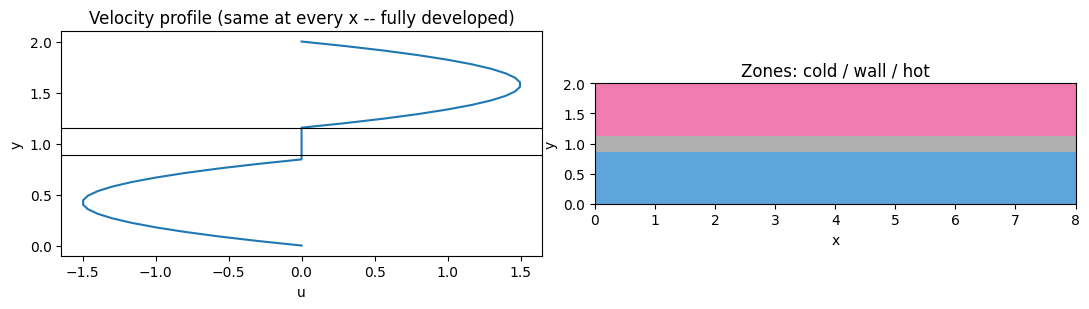

In [5]:
# Look at the inputs before solving anything.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))

axes[0].plot(u[:, 0], y1)
axes[0].axhline(y1[ny_cold], color='k', lw=0.8)
axes[0].axhline(y1[ny_cold + ny_wall], color='k', lw=0.8)
axes[0].set_xlabel('u'); axes[0].set_ylabel('y')
axes[0].set_title('Velocity profile (same at every x -- fully developed)')

axes[1].contourf(X, Y, zone, levels=[-0.5, 0.5, 1.5, 2.5], colors=['#5da5da', '#b0b0b0', '#f17cb0'])
axes[1].set_xlabel('x'); axes[1].set_ylabel('y'); axes[1].set_title('Zones: cold / wall / hot')
axes[1].set_aspect('equal')

plt.tight_layout(); plt.show()

In [6]:
# ============================== 4. Finite-difference building blocks ==============================
def apply_bc(T, ny_cold, ny_wall, ny_hot, T_hot_in, T_cold_in, counter_flow):
    """Every boundary from the table above, in the same order."""
    # hot channel: inlet at x=0, zero-gradient outlet at x=Lx
    T[ny_cold + ny_wall:, 0] = T_hot_in
    T[ny_cold + ny_wall:, -1] = T[ny_cold + ny_wall:, -2]

    # cold channel: inlet/outlet columns swap with the flow direction
    if counter_flow:
        T[:ny_cold, -1] = T_cold_in
        T[:ny_cold, 0] = T[:ny_cold, 1]
    else:
        T[:ny_cold, 0] = T_cold_in
        T[:ny_cold, -1] = T[:ny_cold, -2]

    # wall: no axial heat loss out its own ends
    T[ny_cold:ny_cold + ny_wall, 0] = T[ny_cold:ny_cold + ny_wall, 1]
    T[ny_cold:ny_cold + ny_wall, -1] = T[ny_cold:ny_cold + ny_wall, -2]

    # top and bottom of the whole domain: insulated outer surfaces
    T[0, :] = T[1, :]
    T[-1, :] = T[-2, :]
    return T


def fdm_step(T, u, D, dx, dy, dt):
    """One explicit step of the equation from the discretisation section above, verbatim."""
    Tc = T[1:-1, 1:-1]
    Te, Tw = T[1:-1, 2:], T[1:-1, :-2]
    Tn, Ts = T[2:, 1:-1], T[:-2, 1:-1]

    Dc = D[1:-1, 1:-1]
    D_e = 2 * Dc * D[1:-1, 2:] / (Dc + D[1:-1, 2:])     # harmonic mean at each half-node
    D_w = 2 * Dc * D[1:-1, :-2] / (Dc + D[1:-1, :-2])
    D_n = 2 * Dc * D[2:, 1:-1] / (Dc + D[2:, 1:-1])
    D_s = 2 * Dc * D[:-2, 1:-1] / (Dc + D[:-2, 1:-1])

    diffusion_x = (D_e * (Te - Tc) - D_w * (Tc - Tw)) / dx**2
    diffusion_y = (D_n * (Tn - Tc) - D_s * (Tc - Ts)) / dy**2

    uc = u[1:-1, 1:-1]
    dTdx_upwind = np.where(uc >= 0, (Tc - Tw) / dx, (Te - Tc) / dx)

    T_new = T.copy()
    T_new[1:-1, 1:-1] = Tc + dt * (diffusion_x + diffusion_y - uc * dTdx_upwind)
    return T_new


def stable_time_step(D, u, dx, dy, safety=0.4):
    """Diffusive limit and CFL limit, whichever is tighter, times a safety factor."""
    diffusive_limit = 1.0 / (2.0 * D.max() * (1.0 / dx**2 + 1.0 / dy**2))
    u_max = np.abs(u).max()
    cfl_limit = dx / u_max if u_max > 0 else np.inf
    return safety * min(diffusive_limit, cfl_limit)

In [7]:
# ============================== 5. Solve ==============================
T = np.full((ny, nx), 0.5 * (T_hot_in + T_cold_in))
T[:ny_cold] = T_cold_in
T[ny_cold + ny_wall:] = T_hot_in
T[ny_cold:ny_cold + ny_wall] = np.linspace(T_cold_in, T_hot_in, ny_wall)[:, None]
apply_bc(T, ny_cold, ny_wall, ny_hot, T_hot_in, T_cold_in, counter_flow)

dt = stable_time_step(D, u, dx, dy, safety=dt_safety)

residual_history = []
for iteration in range(1, max_iterations + 1):
    T_old = T
    T = fdm_step(T, u, D, dx, dy, dt)
    apply_bc(T, ny_cold, ny_wall, ny_hot, T_hot_in, T_cold_in, counter_flow)

    residual = np.max(np.abs(T - T_old))
    residual_history.append(residual)

    if not np.all(np.isfinite(T)):
        raise FloatingPointError(f"solution diverged at iteration {iteration} -- check dt / inputs")

    if iteration == 1 or iteration % 2000 == 0:
        print(f"iteration {iteration:6d}   residual = {residual:.3e}")

    if residual < tol and iteration > 50:
        break

print(f"\nstopped after {iteration} iterations,  dt = {dt:.5f},  final residual = {residual:.3e}")

iteration      1   residual = 2.247e-02


iteration   2000   residual = 4.259e-05


iteration   4000   residual = 1.237e-05


iteration   6000   residual = 3.942e-06


iteration   8000   residual = 1.304e-06


iteration  10000   residual = 4.370e-07


iteration  12000   residual = 1.471e-07

stopped after 12000 iterations,  dt = 0.00777,  final residual = 1.471e-07


## Results

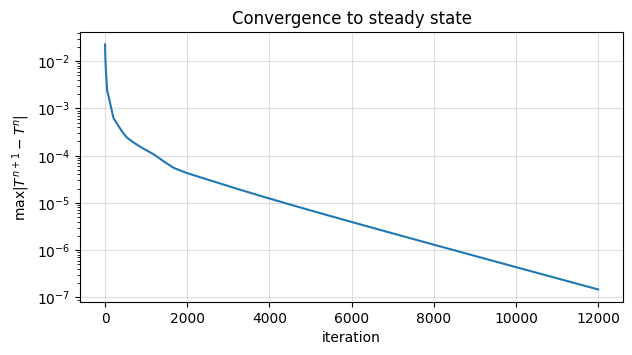

In [8]:
plt.figure(figsize=(7, 3.5))
plt.semilogy(residual_history)
plt.xlabel('iteration'); plt.ylabel(r'$\max|T^{n+1}-T^n|$')
plt.title('Convergence to steady state')
plt.grid(True, alpha=0.4)
plt.show()

In [9]:
def trapezoidal_integral(values, coordinates):
    """A plain trapezoidal rule, used instead of np.trapz so this notebook
    doesn't depend on a specific numpy version (np.trapz was removed in numpy 2.0)."""
    values = np.asarray(values, dtype=float)
    coordinates = np.asarray(coordinates, dtype=float)
    return float(np.sum(0.5 * (values[1:] + values[:-1]) * np.diff(coordinates)))


def bulk_temperature(T_slice, u_slice):
    """Velocity-weighted ('mixing-cup') mean temperature across a channel.
    T_slice, u_slice: either a single column (-> a number) or the whole
    channel (-> a profile along x, since the grid spacing is uniform)."""
    weights = np.abs(u_slice) + 1e-12
    return np.average(T_slice, axis=0, weights=weights)

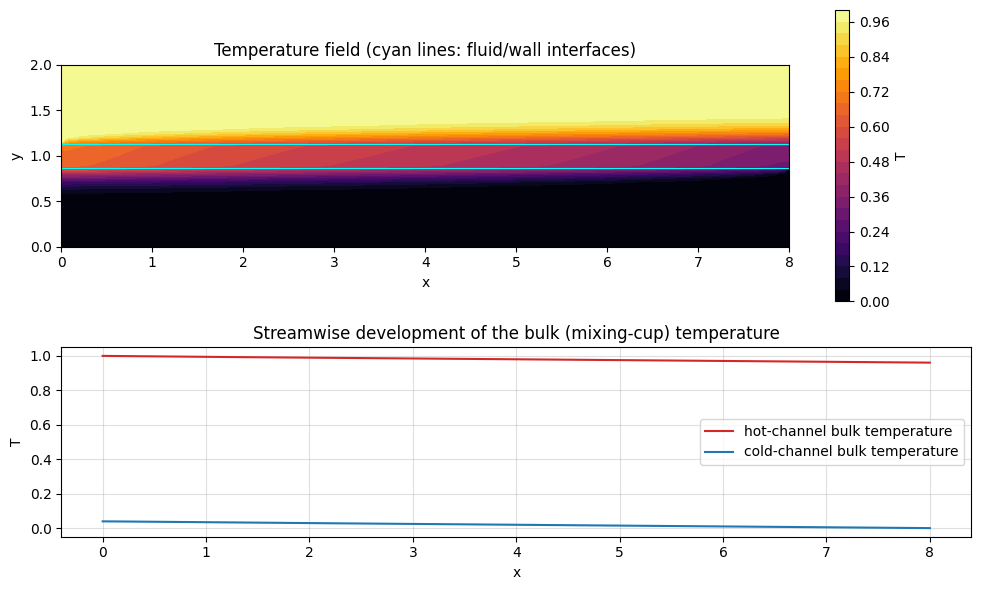

In [10]:
hot_rows = slice(ny_cold + ny_wall, ny)
cold_in_col, cold_out_col = (-1, 0) if counter_flow else (0, -1)

# Bulk temperature is the physically meaningful average across a channel -- the
# centreline barely moves at these Peclet numbers (most of the change is
# concentrated near the wall), so this is what actually shows the streamwise
# development, and it's exactly what the outlet numbers below are built from.
hot_bulk = bulk_temperature(T[hot_rows, :], u[hot_rows, :])
cold_bulk = bulk_temperature(T[:ny_cold, :], u[:ny_cold, :])

fig, axes = plt.subplots(2, 1, figsize=(10, 6), height_ratios=[2, 1.3])

cf = axes[0].contourf(X, Y, T, levels=30, cmap='inferno')
axes[0].contour(X, Y, zone, levels=[0.5, 1.5], colors='cyan', linewidths=0.8)   # fluid/wall interfaces
plt.colorbar(cf, ax=axes[0], label='T')
axes[0].set_xlabel('x'); axes[0].set_ylabel('y')
axes[0].set_title('Temperature field (cyan lines: fluid/wall interfaces)')
axes[0].set_aspect('equal')

axes[1].plot(x1, hot_bulk, label='hot-channel bulk temperature', color='#d62728')
axes[1].plot(x1, cold_bulk, label='cold-channel bulk temperature', color='#1f77b4')
axes[1].set_xlabel('x'); axes[1].set_ylabel('T')
axes[1].set_title('Streamwise development of the bulk (mixing-cup) temperature')
axes[1].legend(); axes[1].grid(True, alpha=0.4)

plt.tight_layout(); plt.show()

In [11]:
hot_in_T = float(bulk_temperature(T[hot_rows, 0], u[hot_rows, 0]))
hot_out_T = float(bulk_temperature(T[hot_rows, -1], u[hot_rows, -1]))
cold_in_T = float(bulk_temperature(T[:ny_cold, cold_in_col], u[:ny_cold, cold_in_col]))
cold_out_T = float(bulk_temperature(T[:ny_cold, cold_out_col], u[:ny_cold, cold_out_col]))

mdot_hot = trapezoidal_integral(np.maximum(u[hot_rows, 0], 0.0), y1[hot_rows])
mdot_cold = trapezoidal_integral(np.abs(u[:ny_cold, cold_in_col]), y1[:ny_cold])

q_hot = mdot_hot * (hot_in_T - hot_out_T)      # heat lost by the hot stream
q_cold = mdot_cold * (cold_out_T - cold_in_T)   # heat gained by the cold stream
imbalance = abs(q_hot - q_cold) / max(abs(q_hot), abs(q_cold), 1e-30)

q_max = min(mdot_hot, mdot_cold) * (T_hot_in - T_cold_in)
effectiveness = q_cold / max(q_max, 1e-30)

print(f"hot   inlet -> outlet :  {hot_in_T:.4f} -> {hot_out_T:.4f}")
print(f"cold  inlet -> outlet :  {cold_in_T:.4f} -> {cold_out_T:.4f}")
print(f"heat lost by hot stream    q_hot  = {q_hot:.5f}")
print(f"heat gained by cold stream q_cold = {q_cold:.5f}")
print(f"relative energy imbalance         = {imbalance:.2e}   "
      f"(tiny by construction -- the FDM's own conservation check)")
print(f"effectiveness  epsilon = q_cold / q_max = {effectiveness:.4f}")

hot   inlet -> outlet :  1.0000 -> 0.9608
cold  inlet -> outlet :  0.0000 -> 0.0392
heat lost by hot stream    q_hot  = 0.03301
heat gained by cold stream q_cold = 0.03301
relative energy imbalance         = 1.04e-13   (tiny by construction -- the FDM's own conservation check)
effectiveness  epsilon = q_cold / q_max = 0.0392


### Optional: export for ParaView

The report checklist only asks for this if it's specifically assigned — the inline plots above are enough for the required figure.

In [12]:
def write_vtk(path, x1, y1, T, zone):
    """Minimal legacy VTK structured-grid writer -- just the two scalar fields we have."""
    nx, ny = len(x1), len(y1)
    with open(path, 'w') as f:
        f.write("# vtk DataFile Version 3.0\ndouble-pipe CHT\nASCII\nDATASET STRUCTURED_GRID\n")
        f.write(f"DIMENSIONS {nx} {ny} 1\nPOINTS {nx * ny} float\n")
        for j in range(ny):
            for i in range(nx):
                f.write(f"{x1[i]:.6e} {y1[j]:.6e} 0\n")
        f.write(f"POINT_DATA {nx * ny}\nSCALARS temperature float 1\nLOOKUP_TABLE default\n")
        for j in range(ny):
            for i in range(nx):
                f.write(f"{T[j, i]:.6e}\n")
        f.write("SCALARS zone float 1\nLOOKUP_TABLE default\n")
        for j in range(ny):
            for i in range(nx):
                f.write(f"{zone[j, i]:.1f}\n")


write_vtk('double_pipe_cht.vtk', x1, y1, T, zone)
print("wrote double_pipe_cht.vtk")

wrote double_pipe_cht.vtk


## Compulsory assignment

Run $Re=50,100,200$ (with $Re_{hot}=Re_{cold}$) and compare outlet temperatures, heat-transfer rate, effectiveness, and energy imbalance. Repeat one case for conductivity ratios $k_s/k_f=1$ and $100$.

The cells below wrap the exact steps above into one function, `solve_double_pipe`, so the sweep doesn't need the loop copy-pasted for every case.

### Report checklist
- State the governing equations and boundary conditions.
- Report the complete parameter set and grid.
- Include the residual history.
- Include the required quantitative comparison (table and/or plot).
- Include at least one correctly labelled field figure.
- Distinguish observed numerical behaviour from physical interpretation.
- State the limitations of this teaching model (planar idealisation of the pipe geometry, prescribed rather than solved velocity field, first-order-accurate upwinding).

In [13]:
def solve_double_pipe(Re_hot, Re_cold, Pr, ks_by_kf, counter_flow,
                       T_hot_in=1.0, T_cold_in=0.0, U_hot=1.0, U_cold=1.0,
                       nx=nx, ny_cold=ny_cold, ny_wall=ny_wall, ny_hot=ny_hot,
                       Lx=Lx, Ly=Ly, max_iterations=12000, tol=1e-8, safety=0.4, verbose=False, save_history=False):
    """The grid/velocity/diffusivity/solve steps above, packaged for a parameter sweep."""
    ny = ny_cold + ny_wall + ny_hot
    x1 = np.linspace(0.0, Lx, nx)
    y1 = np.linspace(0.0, Ly, ny)
    dx, dy = x1[1] - x1[0], y1[1] - y1[0]

    zone = np.zeros((ny, nx), dtype=int)
    zone[ny_cold:ny_cold + ny_wall] = 1
    zone[ny_cold + ny_wall:] = 2

    u = velocity_field(ny_cold, ny_wall, ny_hot, nx, U_cold, U_hot, counter_flow)
    D_cold_, D_hot_ = 1.0 / (Re_cold * Pr), 1.0 / (Re_hot * Pr)
    D_wall_ = ks_by_kf * 0.5 * (D_hot_ + D_cold_)
    D = np.where(zone == 0, D_cold_, np.where(zone == 1, D_wall_, D_hot_))

    T = np.full((ny, nx), 0.5 * (T_hot_in + T_cold_in))
    T[:ny_cold] = T_cold_in
    T[ny_cold + ny_wall:] = T_hot_in
    T[ny_cold:ny_cold + ny_wall] = np.linspace(T_cold_in, T_hot_in, ny_wall)[:, None]
    apply_bc(T, ny_cold, ny_wall, ny_hot, T_hot_in, T_cold_in, counter_flow)

    dt = stable_time_step(D, u, dx, dy, safety=safety)
    residual_history = []
    hot_out_history = []
    cold_out_history = []
    for iteration in range(1, max_iterations + 1):
        T_old = T
        T = fdm_step(T, u, D, dx, dy, dt)
        apply_bc(T, ny_cold, ny_wall, ny_hot, T_hot_in, T_cold_in, counter_flow)
        residual = np.max(np.abs(T - T_old))
        residual_history.append(residual)
        # Record bulk outlet temperatures after applying boundary conditions
        hot_rows_iter = slice(ny_cold + ny_wall, ny)
        cold_in_col_iter, cold_out_col_iter = (-1, 0) if counter_flow else (0, -1)
        hot_out_history.append(float(bulk_temperature(
            T[hot_rows_iter, -1], u[hot_rows_iter, -1])))
        cold_out_history.append(float(bulk_temperature(
            T[:ny_cold, cold_out_col_iter], u[:ny_cold, cold_out_col_iter])))
        if not np.all(np.isfinite(T)):
            raise FloatingPointError(f"diverged at iteration {iteration}")
        if residual < tol and iteration > 50:
            break
    if verbose:
        print(f"  Re_hot={Re_hot:g} Re_cold={Re_cold:g} ks/kf={ks_by_kf:g}: "
              f"{iteration} iterations, residual={residual:.2e}")

    hot_rows = slice(ny_cold + ny_wall, ny)
    cold_in_col, cold_out_col = (-1, 0) if counter_flow else (0, -1)
    hot_in_T = float(bulk_temperature(T[hot_rows, 0], u[hot_rows, 0]))
    hot_out_T = float(bulk_temperature(T[hot_rows, -1], u[hot_rows, -1]))
    cold_in_T = float(bulk_temperature(T[:ny_cold, cold_in_col], u[:ny_cold, cold_in_col]))
    cold_out_T = float(bulk_temperature(T[:ny_cold, cold_out_col], u[:ny_cold, cold_out_col]))
    mdot_hot = trapezoidal_integral(np.maximum(u[hot_rows, 0], 0.0), y1[hot_rows])
    mdot_cold = trapezoidal_integral(np.abs(u[:ny_cold, cold_in_col]), y1[:ny_cold])
    q_hot = mdot_hot * (hot_in_T - hot_out_T)
    q_cold = mdot_cold * (cold_out_T - cold_in_T)
    imbalance = abs(q_hot - q_cold) / max(abs(q_hot), abs(q_cold), 1e-30)
    effectiveness = q_cold / max(min(mdot_hot, mdot_cold) * (T_hot_in - T_cold_in), 1e-30)

    return dict(T=T, x1=x1, y1=y1, zone=zone, u=u, D=D, iterations=iteration,
                hot_in=hot_in_T, hot_out=hot_out_T, cold_in=cold_in_T, cold_out=cold_out_T,
                q_hot=q_hot, q_cold=q_cold, imbalance=imbalance, effectiveness=effectiveness,
                residual_history=residual_history, hot_out_history=hot_out_history,
                cold_out_history=cold_out_history)

Re sweep (ks/kf = 20, counter-flow):


  Re_hot=50 Re_cold=50 ks/kf=20: 12000 iterations, residual=5.09e-07


  Re_hot=100 Re_cold=100 ks/kf=20: 12000 iterations, residual=1.47e-07


  Re_hot=200 Re_cold=200 ks/kf=20: 12000 iterations, residual=8.99e-08

    Re    hot_out   cold_out     q_cold    imbalance  effectiveness
    50     0.9356     0.0644    0.05427     5.20e-14         0.0644
   100     0.9608     0.0392    0.03301     1.04e-13         0.0392
   200     0.9765     0.0235    0.01979     1.47e-13         0.0235


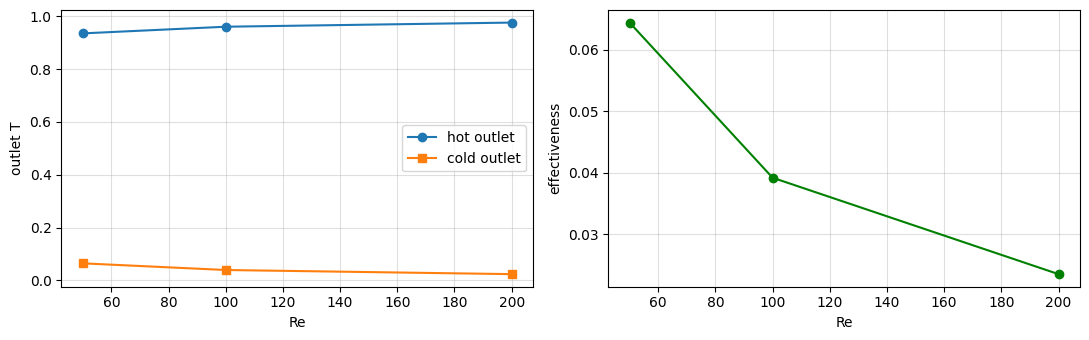

In [14]:
print("Re sweep (ks/kf = 20, counter-flow):")
re_results = []
for Re in [50, 100, 200]:
    r = solve_double_pipe(Re_hot=Re, Re_cold=Re, Pr=Pr, ks_by_kf=20.0, counter_flow=True, verbose=True)
    re_results.append((Re, r))

print(f"\n{'Re':>6} {'hot_out':>10} {'cold_out':>10} {'q_cold':>10} {'imbalance':>12} {'effectiveness':>14}")
for Re, r in re_results:
    print(f"{Re:6d} {r['hot_out']:10.4f} {r['cold_out']:10.4f} {r['q_cold']:10.5f} "
          f"{r['imbalance']:12.2e} {r['effectiveness']:14.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
Res = [Re for Re, r in re_results]
axes[0].plot(Res, [r['hot_out'] for Re, r in re_results], 'o-', label='hot outlet')
axes[0].plot(Res, [r['cold_out'] for Re, r in re_results], 's-', label='cold outlet')
axes[0].set_xlabel('Re'); axes[0].set_ylabel('outlet T'); axes[0].legend(); axes[0].grid(alpha=0.4)
axes[1].plot(Res, [r['effectiveness'] for Re, r in re_results], 'o-', color='green')
axes[1].set_xlabel('Re'); axes[1].set_ylabel('effectiveness'); axes[1].grid(alpha=0.4)
plt.tight_layout(); plt.show()

In [15]:
print("Conductivity-ratio sweep (Re_hot = Re_cold = 100, counter-flow):")
ks_results = []
for ks in [1.0, 100.0]:
    r = solve_double_pipe(Re_hot=100.0, Re_cold=100.0, Pr=Pr, ks_by_kf=ks, counter_flow=True, verbose=True)
    ks_results.append((ks, r))

print(f"\n{'ks/kf':>8} {'hot_out':>10} {'cold_out':>10} {'effectiveness':>14}")
for ks, r in ks_results:
    print(f"{ks:8.0f} {r['hot_out']:10.4f} {r['cold_out']:10.4f} {r['effectiveness']:14.4f}")

Conductivity-ratio sweep (Re_hot = Re_cold = 100, counter-flow):


  Re_hot=100 Re_cold=100 ks/kf=1: 12000 iterations, residual=1.10e-08


  Re_hot=100 Re_cold=100 ks/kf=100: 12000 iterations, residual=5.11e-06

   ks/kf    hot_out   cold_out  effectiveness
       1     0.9775     0.0225         0.0225
     100     0.9601     0.0399         0.0399


  Re_hot=51 Re_cold=51 ks/kf=1: 7783 iterations, residual=1.00e-08


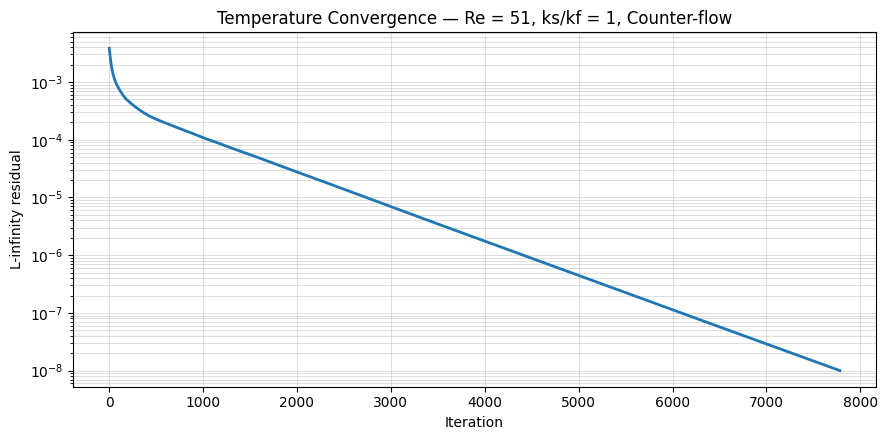

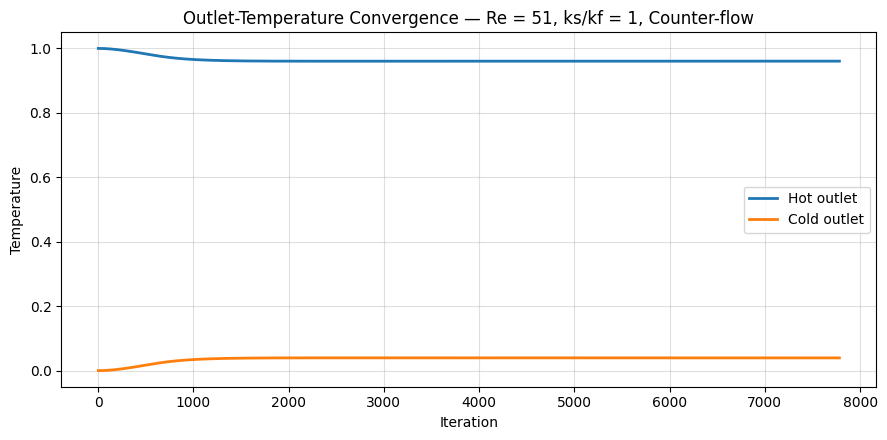

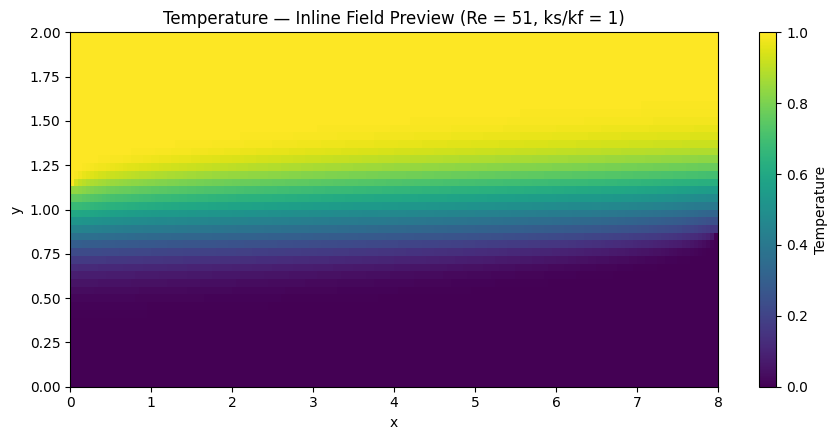

Re=51 outlet results: hot=0.960540, cold=0.039460; iterations=7783


In [16]:

# ============================== Re = 51: requested graphs ==============================
# Counter-flow; both stream Reynolds numbers are 51; wall/fluid conductivity ratio = 1.
r51 = solve_double_pipe(
    Re_hot=51, Re_cold=51, Pr=Pr, ks_by_kf=1.0,
    counter_flow=True, verbose=True
)

# 1) Residual convergence (log scale)
plt.figure(figsize=(9, 4.5))
plt.semilogy(np.arange(1, len(r51["residual_history"]) + 1),
             r51["residual_history"], linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("L-infinity residual")
plt.title("Temperature Convergence — Re = 51, ks/kf = 1, Counter-flow")
plt.grid(True, which="both", alpha=0.4)
plt.tight_layout()
plt.savefig("Re51_graph_1.png", dpi=200, bbox_inches="tight")
plt.show()

# 2) Outlet-temperature convergence
plt.figure(figsize=(9, 4.5))
plt.plot(np.arange(1, len(r51["hot_out_history"]) + 1),
         r51["hot_out_history"], label="Hot outlet", linewidth=2)
plt.plot(np.arange(1, len(r51["cold_out_history"]) + 1),
         r51["cold_out_history"], label="Cold outlet", linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("Temperature")
plt.title("Outlet-Temperature Convergence — Re = 51, ks/kf = 1, Counter-flow")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig("Re51_graph_2.png", dpi=200, bbox_inches="tight")
plt.show()

# 3) Temperature field, matching the inline field-preview style
plt.figure(figsize=(9, 4.5))
plt.imshow(r51["T"], origin="lower", aspect="auto", cmap="viridis",
           extent=[0, Lx, 0, Ly])
plt.colorbar(label="Temperature")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Temperature — Inline Field Preview (Re = 51, ks/kf = 1)")
plt.tight_layout()
plt.savefig("Re51_graph_3.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Re=51 outlet results: hot={r51['hot_out']:.6f}, "
      f"cold={r51['cold_out']:.6f}; iterations={r51['iterations']}")
